HIRA GHAZI
BATCH 16 AI AND DATA SCIENCE

Employee Salaries Analysis


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [ ]:
from pathlib import Path
csv_path = Path("data/Employee_Salaries_raw.csv")
if not csv_path.exists():
    csv_path = Path("/content/Employee_Salaries.csv")
df = pd.read_csv(csv_path)
df

,Department,Department_Name,Division,Gender,Base_Salary,Overtime_Pay,Longevity_Pay,Grade
0,ABS,Alcohol Beverage Services,ABS 85 Administration,M,175873.0000,0.00,0.00,M2
1,ABS,Alcohol Beverage Services,ABS 85 Administration,M,145613.3600,0.00,0.00,M3
2,ABS,Alcohol Beverage Services,ABS 85 Administration,F,136970.0000,0.00,0.00,M3
3,ABS,Alcohol Beverage Services,ABS 85 Administrative Services,F,89432.6940,0.00,2490.00,21
4,ABS,Alcohol Beverage Services,ABS 85 Administrative Services,F,78947.0000,456.68,6257.70,16
...,...,...,...,...,...,...,...,...
10286,TBS,Department of Technology and Enterprise Busine...,TBS 34 OSP Low Code Governance and Administration,M,134500.0000,0.00,0.00,N28
10287,ZAH,Office of Zoning and Administrative Hearings,ZAH 05 Director,F,215032.1000,0.00,0.00,NaN
10288,ZAH,Office of Zoning and Administrative Hearings,ZAH 05 Office of Zoning and Administrative Hea...,F,84365.5529,0.00,0.00,N18
10289,ZAH,Office of Zoning and Administrative Hearings,ZAH 05 Zoning and Administrative Hearings,F,98228.0000,0.00,1596.27,N21


In [ ]:
df.head()

,Department,Department_Name,Division,Gender,Base_Salary,Overtime_Pay,Longevity_Pay,Grade
0,ABS,Alcohol Beverage Services,ABS 85 Administration,M,175873.000,0.00,0.0,M2
1,ABS,Alcohol Beverage Services,ABS 85 Administration,M,145613.360,0.00,0.0,M3
2,ABS,Alcohol Beverage Services,ABS 85 Administration,F,136970.000,0.00,0.0,M3
3,ABS,Alcohol Beverage Services,ABS 85 Administrative Services,F,89432.694,0.00,2490.0,21
4,ABS,Alcohol Beverage Services,ABS 85 Administrative Services,F,78947.000,456.68,6257.7,16


In [ ]:
df.shape

(10291, 8)

In [ ]:
df.columns

Index(['Department', 'Department_Name', 'Division', 'Gender', 'Base_Salary',
       'Overtime_Pay', 'Longevity_Pay', 'Grade'],
      dtype='object')

In [ ]:
df.describe()

,Base_Salary,Overtime_Pay,Longevity_Pay
count,10291.000000,10291.000000,10291.000000
mean,90312.165744,8081.288954,1533.882816
std,31240.842929,16491.833017,3209.041070
min,11147.240000,0.000000,0.000000
25%,70023.000000,0.000000,0.000000
50%,87328.000000,258.420000,0.000000
75%,108084.000000,9190.970000,1225.680000
max,292000.000000,227428.990000,20279.460000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10291 entries, 0 to 10290
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Department       10291 non-null  object 
 1   Department_Name  10291 non-null  object 
 2   Division         10291 non-null  object 
 3   Gender           10291 non-null  object 
 4   Base_Salary      10291 non-null  float64
 5   Overtime_Pay     10291 non-null  float64
 6   Longevity_Pay    10291 non-null  float64
 7   Grade            10258 non-null  object 
dtypes: float64(3), object(5)
memory usage: 643.3+ KB


In [ ]:
df.describe(include="object")

,Department,Department_Name,Division,Gender,Grade
count,10291,10291,10291,10291,10258
unique,42,42,627,2,98
top,HHS,Department of Health and Human Services,HHS 60 School Health Services,M,T1
freq,1877,1877,399,5929,687


In [11]:
df.isnull().sum()

,0
Department,0
Department_Name,0
Division,0
Gender,0
Base_Salary,0
Overtime_Pay,0
Longevity_Pay,0
Grade,33


In [12]:
df.nunique()

,0
Department,42
Department_Name,42
Division,627
Gender,2
Base_Salary,3470
Overtime_Pay,5566
Longevity_Pay,1113
Grade,98


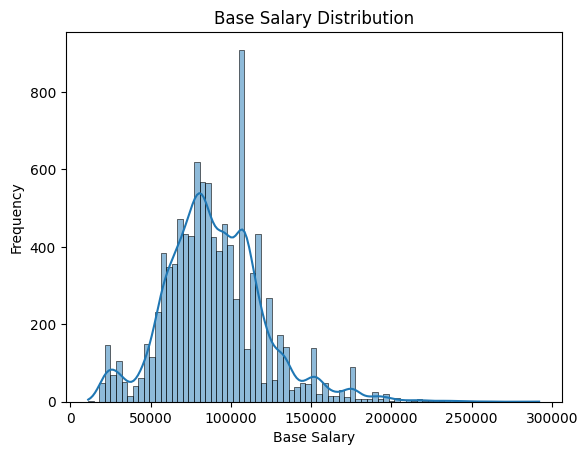

In [13]:
sns.histplot(df["Base_Salary"], kde=True)
plt.title("Base Salary Distribution")
plt.xlabel("Base Salary")
plt.ylabel("Frequency")
plt.show()

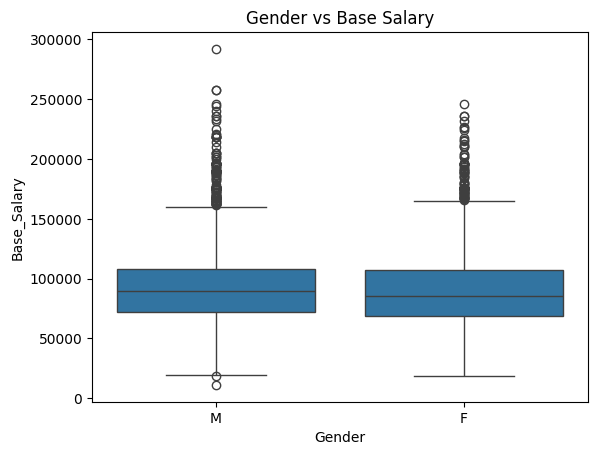

In [14]:
sns.boxplot(data=df, x="Gender", y="Base_Salary")
plt.title("Gender vs Base Salary")
plt.show()

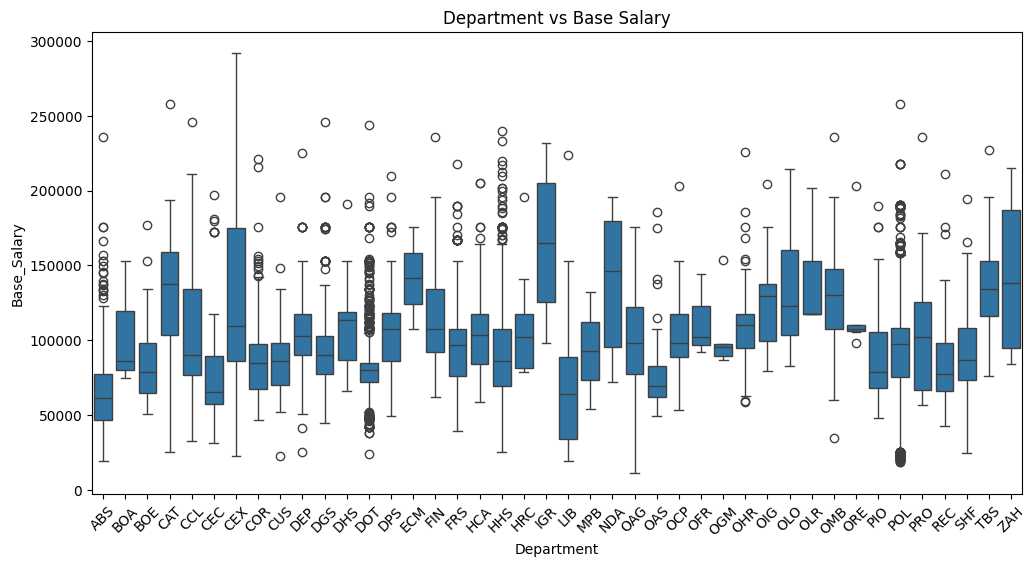

In [15]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="Department", y="Base_Salary")

plt.title("Department vs Base Salary")
plt.xticks(rotation=45)
plt.show()

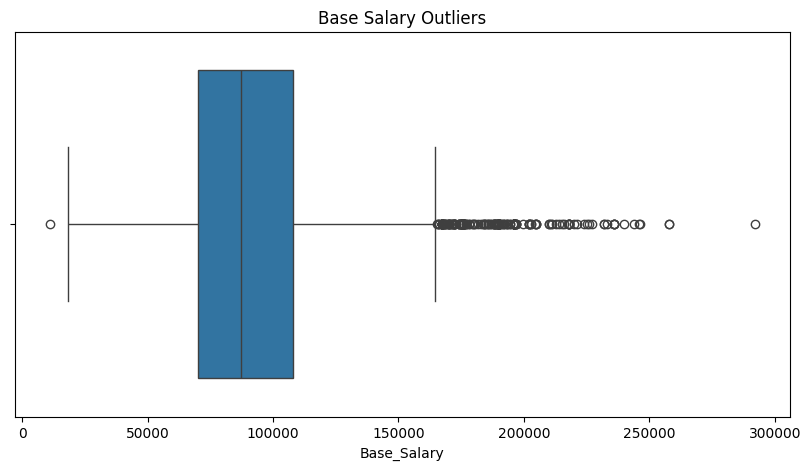

In [16]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Base_Salary"])

plt.title("Base Salary Outliers")
plt.show()

In [17]:
Q1 = df["Base_Salary"].quantile(0.25)
Q3 = df["Base_Salary"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)

Lower Limit: 12931.5
Upper Limit: 165175.5


In [18]:
X = df.drop("Base_Salary", axis=1)

y = df["Base_Salary"]

In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [20]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (8232, 7)
X_test: (2059, 7)
y_train: (8232,)
y_test: (2059,)


In [21]:
X_train.isnull().sum()

,0
Department,0
Department_Name,0
Division,0
Gender,0
Overtime_Pay,0
Longevity_Pay,0
Grade,29


In [22]:
num_cols = X_train.select_dtypes(include=np.number).columns

cat_cols = X_train.select_dtypes(include="object").columns

In [23]:
for col in num_cols:
    X_train[col] = X_train[col].fillna(X_train[col].median())
    X_test[col] = X_test[col].fillna(X_train[col].median())

for col in cat_cols:
    X_train[col] = X_train[col].fillna(X_train[col].mode()[0])
    X_test[col] = X_test[col].fillna(X_train[col].mode()[0])

In [24]:
X_train.isnull().sum()

,0
Department,0
Department_Name,0
Division,0
Gender,0
Overtime_Pay,0
Longevity_Pay,0
Grade,0


In [25]:
X_test.isnull().sum()

,0
Department,0
Department_Name,0
Division,0
Gender,0
Overtime_Pay,0
Longevity_Pay,0
Grade,0


In [26]:
train_df = X_train.copy()

train_df["Base_Salary"] = y_train

train_df.duplicated().sum()

np.int64(446)

In [28]:
train_df = train_df.drop_duplicates()

In [29]:
train_df.duplicated().sum()

np.int64(0)

In [30]:
X_train = train_df.drop("Base_Salary", axis=1)
y_train = train_df["Base_Salary"]

In [31]:
num_cols = X_train.select_dtypes(include=np.number).columns

for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = X_train[
        (X_train[col] < lower) | (X_train[col] > upper)
    ]

    print(col, "Outliers:", len(outliers))

Overtime_Pay Outliers: 841
Longevity_Pay Outliers: 1497


In [32]:
clip_bounds = {}

for col in ["Overtime_Pay", "Longevity_Pay"]:

    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    clip_bounds[col] = (float(lower), float(upper))

    X_train[col] = X_train[col].clip(lower, upper)
    X_test[col] = X_test[col].clip(lower, upper)
# Keep readable, cleaned records before one-hot encoding for the dashboard export.
X_train_clean = X_train.copy()
X_test_clean = X_test.copy()


In [33]:
cat_cols = X_train.select_dtypes(include="object").columns

print(cat_cols)

Index(['Department', 'Department_Name', 'Division', 'Gender', 'Grade'], dtype='object')


In [34]:
X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)

X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)

X_train, X_test = X_train.align(X_test, join="left", axis=1, fill_value=0)

In [35]:
X_train.head()

,Overtime_Pay,Longevity_Pay,Department_ABS,Department_BOA,Department_BOE,Department_CAT,Department_CCL,Department_CEC,Department_CEX,Department_COR,...,Grade_N5,Grade_P1,Grade_P2,Grade_P3,Grade_P4,Grade_P4P,Grade_P5,Grade_T1,Grade_T1P,Grade_T2
841,0.00,0.000,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
2119,10155.99,3250.425,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6104,0.00,0.000,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7737,0.00,3250.425,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
994,0.00,0.000,0,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0


In [36]:
X_train.shape

(7786, 795)

In [37]:
X_test.shape

(2059, 795)

In [38]:
from sklearn.preprocessing import StandardScaler

In [39]:
scaler = StandardScaler()

In [40]:
X_train_scaled = scaler.fit_transform(X_train)

In [41]:
X_test_scaled = scaler.transform(X_test)

In [42]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(7786, 795)
(2059, 795)


In [43]:
from sklearn.linear_model import LinearRegression

In [44]:
lr_model = LinearRegression()

In [45]:
lr_model.fit(X_train_scaled, y_train)

LinearRegression()

In [46]:
y_pred_lr = lr_model.predict(X_test_scaled)

In [47]:
print("Actual Salaries:")
print(y_test.head(10).values)

print("\nPredicted Salaries:")
print(y_pred_lr[:10])

Actual Salaries:
[25412.5227 46224.7932 72333.     56493.405  78525.94   56443.
 73871.266  61240.     66572.     25301.7514]

Predicted Salaries:
[26995.40902577 50215.06844042 68080.79086118 68298.89916093
 90236.52690315 40843.52200063 69283.25926989 56003.07758732
 66028.64371488 26995.40902577]


In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [50]:
mae = mean_absolute_error(y_test, y_pred_lr)

mse = mean_squared_error(y_test, y_pred_lr)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred_lr)

In [52]:
from sklearn.metrics import mean_absolute_error, r2_score

print("MAE:", mean_absolute_error(y_test, y_pred_lr))
print("R2 Score:", r2_score(y_test, y_pred_lr))

MAE: 7617.367637791654
R2 Score: 0.8675680983990768


In [53]:
comparison = pd.DataFrame({
    "Actual Salary": y_test.values,
    "Predicted Salary": y_pred_lr
})

comparison.head(10)

,Actual Salary,Predicted Salary
0,25412.5227,26995.409026
1,46224.7932,50215.068440
2,72333.0000,68080.790861
3,56493.4050,68298.899161
4,78525.9400,90236.526903
5,56443.0000,40843.522001
6,73871.2660,69283.259270
7,61240.0000,56003.077587
8,66572.0000,66028.643715
9,25301.7514,26995.409026


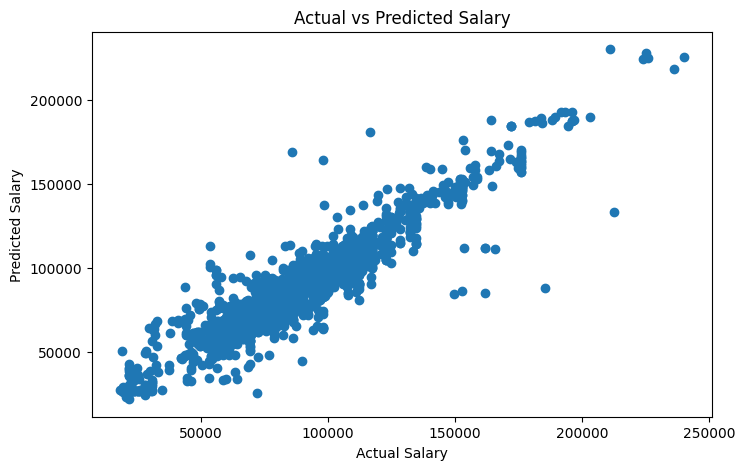

In [54]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_lr)

plt.xlabel("Actual Salary")
plt.ylabel("Predicted Salary")
plt.title("Actual vs Predicted Salary")

plt.show()

In [ ]:
# Export the cleaned records and the fitted preprocessing used by the saved model.
# Run this cell after the full notebook workflow has completed.
from pathlib import Path
import json

project_dir = Path("employee-salary-dashboard") if Path("employee-salary-dashboard").exists() else Path(".")
data_dir = project_dir / "data"
models_dir = project_dir / "models"
data_dir.mkdir(parents=True, exist_ok=True)
models_dir.mkdir(parents=True, exist_ok=True)

cleaned_employee_salaries = pd.concat(
    [
        X_train_clean.assign(Base_Salary=y_train),
        X_test_clean.assign(Base_Salary=y_test),
    ],
    axis=0,
    ignore_index=True,
)
cleaned_employee_salaries = cleaned_employee_salaries[
    ["Department", "Department_Name", "Division", "Gender", "Base_Salary",
     "Overtime_Pay", "Longevity_Pay", "Grade"]
]
cleaned_employee_salaries.to_csv(
    data_dir / "cleaned_employee_salary.csv", index=False
)

preprocessing = {
    "mean": scaler.mean_.tolist(),
    "scale": scaler.scale_.tolist(),
    "feature_columns": X_train.columns.tolist(),
    "clip_bounds": {key: list(value) for key, value in clip_bounds.items()},
    "categorical_features": list(cat_cols),
}
(models_dir / "inference_preprocessing.json").write_text(
    json.dumps(preprocessing), encoding="utf-8"
)
print(f"Saved {len(cleaned_employee_salaries):,} cleaned employee records")
print(f"CSV: {data_dir / 'cleaned_employee_salary.csv'}")
print(f"Preprocessing: {models_dir / 'inference_preprocessing.json'}")
